## Experiment

In [1]:
import os
for k,v in os.environ.items():
    if k.startswith("QUANTDATA_"):
        print(f"{k}={v}")
        

QUANTDATA_EXPERIMENTS=/media/storage/quantdata/experiments
QUANTDATA_PROCESSING_DATA=/media/storage/quantdata/processing
QUANTDATA_RAW_DATA=/mnt/aae/quantdata
QUANTDATA_TRAINING_DATA=/media/storage/quantdata/training


In [2]:

%load_ext autoreload
%autoreload 1

%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator
%aimport quantdata.dysanos.grid.torch_universe
%aimport quantdata.dysanos.grid.torch_det_measure_change
%aimport quantdata.dysanos.grid.torch_all
%aimport quantdata.dysanos.grid.torch_drift_changeV2

from quantdata.dysanos.grid.torch_all import run_experiment_tight, DysanosExperiment, PrettyObject
import gc
gc.collect()

experiment_config = DysanosExperiment(num_samples=100_000)

ex = run_experiment_tight(
    experiment_config,
    plot_sampler=True,
    plot_det_measure_change=True)
ex = PrettyObject(ex)

print("*** READY ***")

*** READY ***


### Primary measure change

0.0 GiB allocated
0.0 GiB reserved

***Allocated CUDA device cuda:0 with lock file /tmp/locks/quant_data/torch/cuda_0.lck.


### Running Primary with group: dysanosV2

0.0 GiB allocated
0.0 GiB reserved
00: Training drn,outer,cost=2std,u=pexp,noboot,dhg,batched_v2 version 0.6 group 'dysanosV2' for 100000 epochs.
00: Using batches of 20000 samples with learning rate 0.001 and weight decay 0.0001.
00: Instantiating drn,outer,cost=2std,u=pexp,noboot,dhg,batched_v2 version 0.6 on Env(prec=32,device=cuda:0,debug=False)... done; this took 0.11s.
00: Using recovery checkpoint '/home/hans/.dysanos_dhx/dysanosV2/drn,outer,cost=2std,u=pexp,noboot,dhg,b a75838be.pt'.
00: Copied 7 arrays with a total size 2070.62MB to Env(prec=32,device=cuda:0,debug=False). This took 0.41s.                          
00: Initial training loss is 0.002362 and validation loss 0.002637. This took 0.43s.


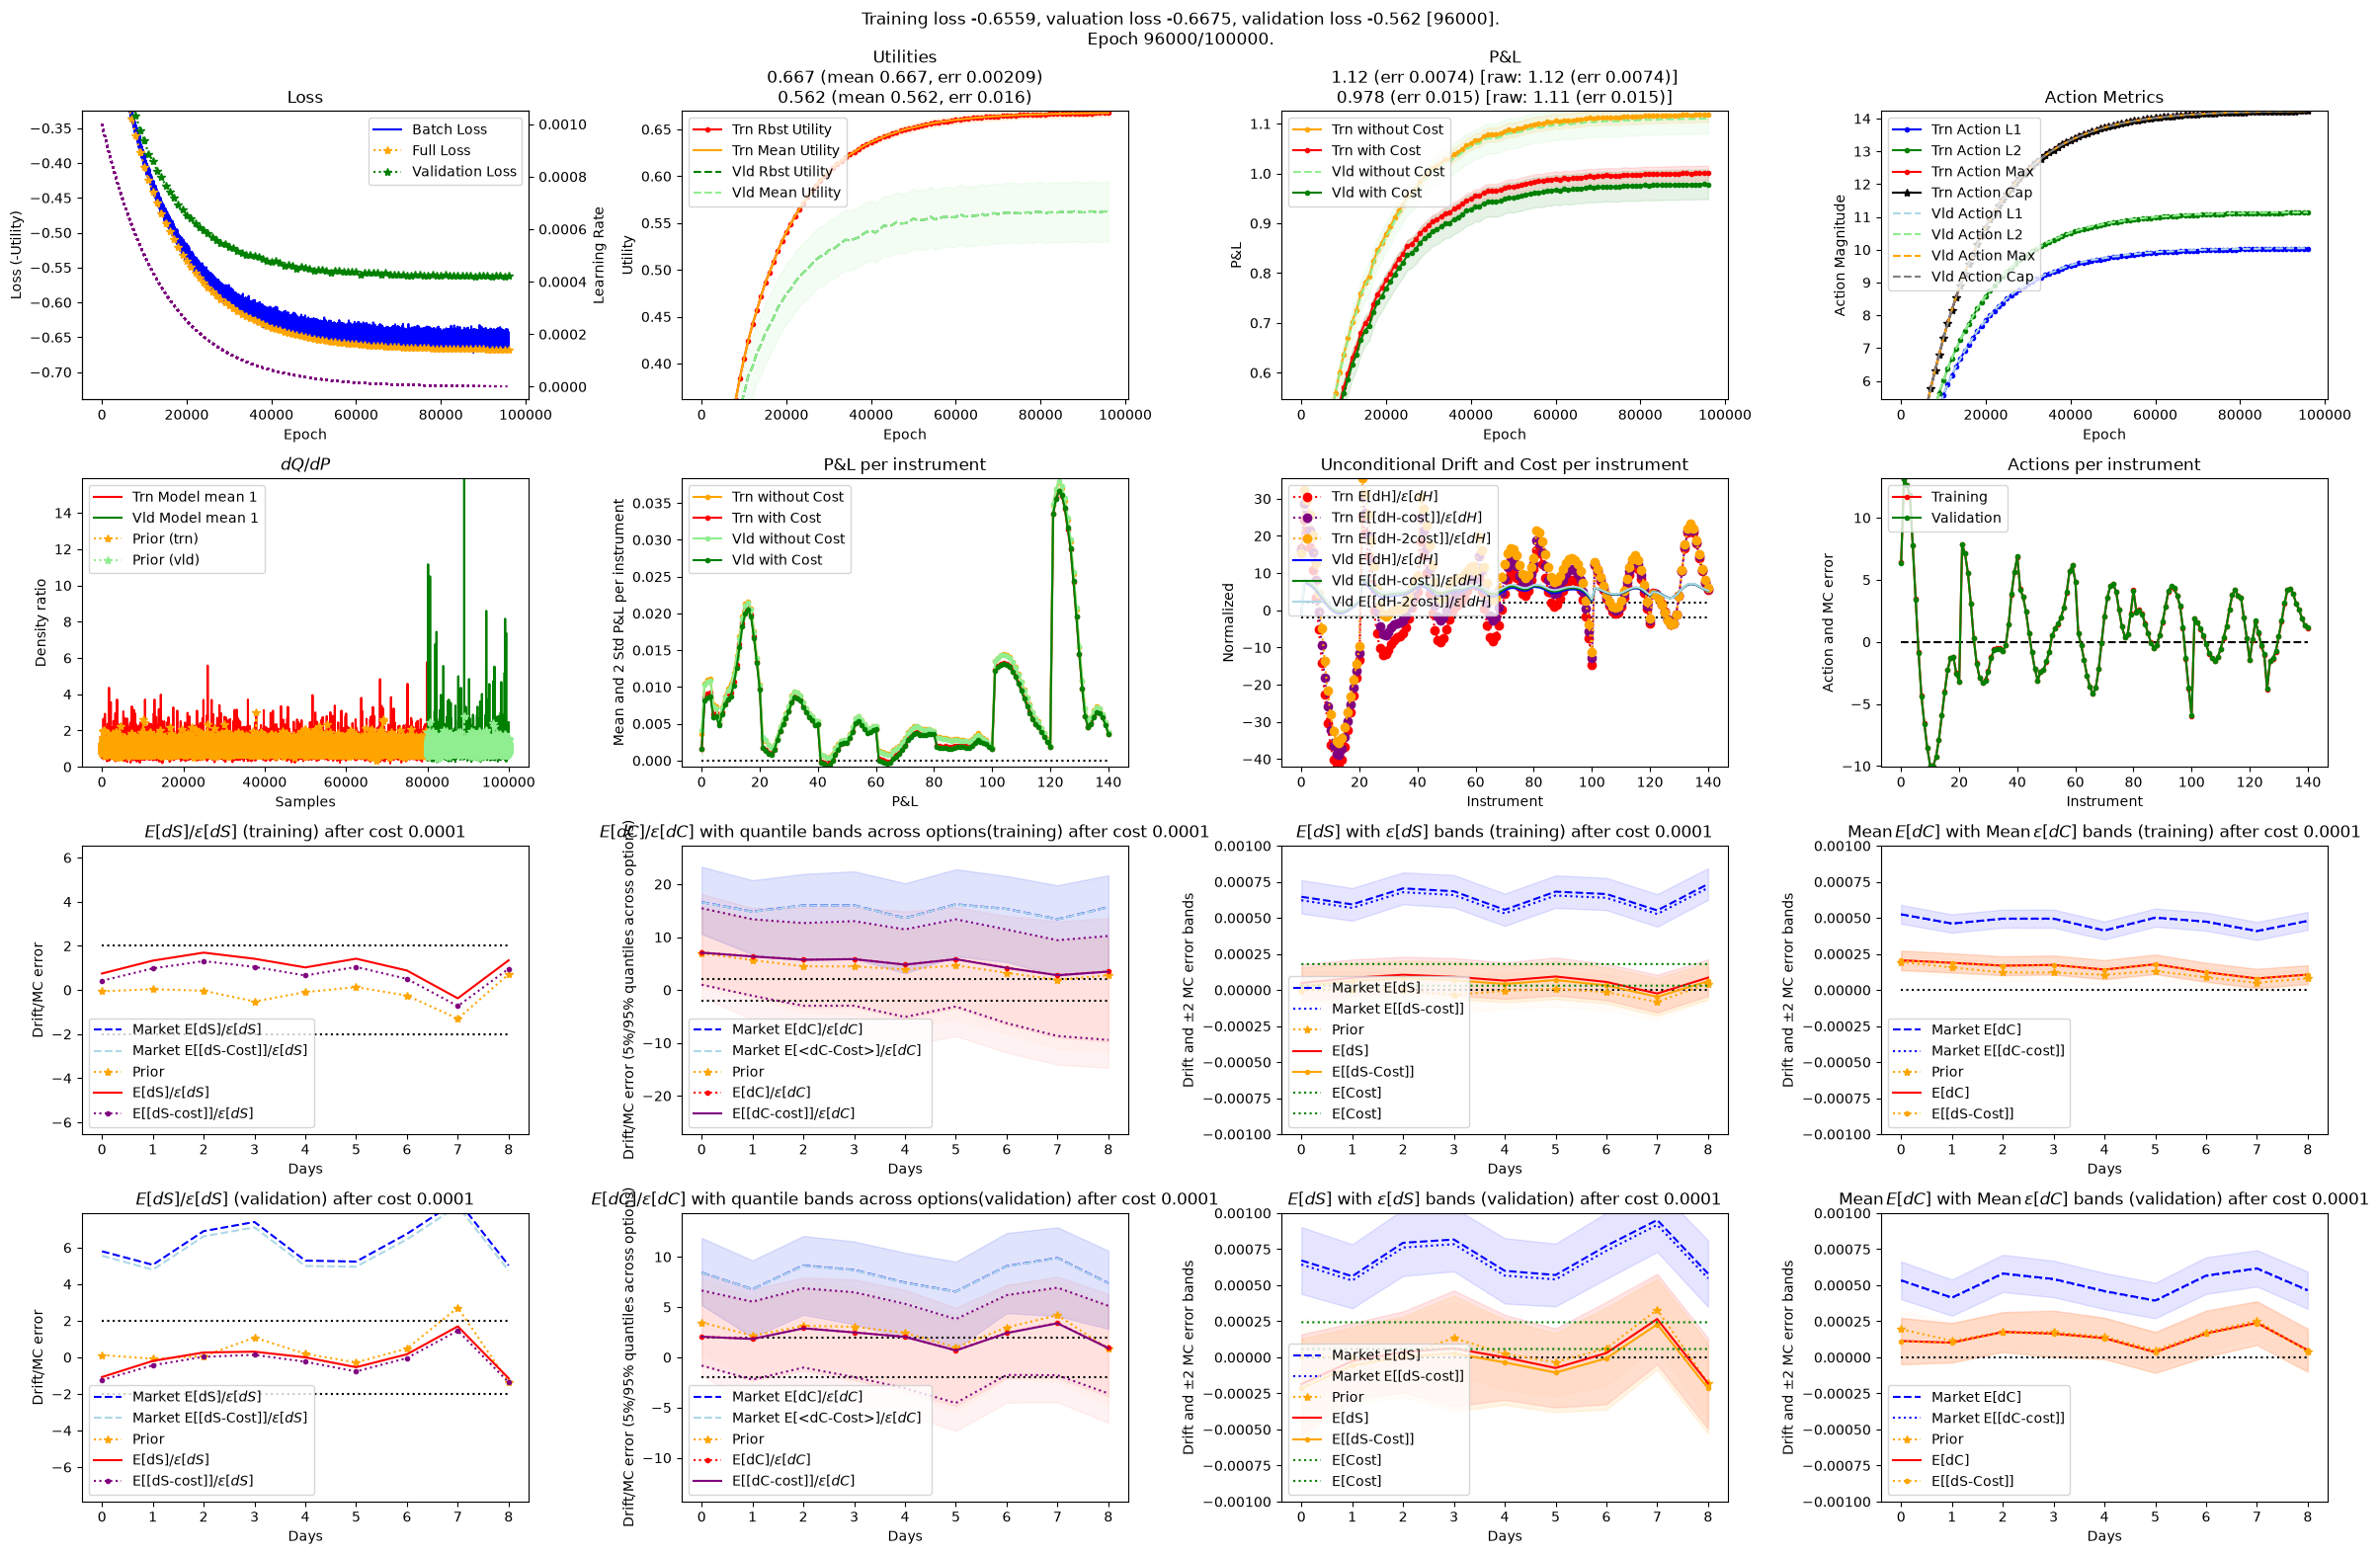

00: Training drn,outer,cost=2std,u=pexp,noboot,dhg,batched_v2@dysanosV2 0.6 with epochs=100000,lr=0.001->1e-06,wdec=0.0001,bsize=20000,vbsize=all,pcnt_val=0.20,compile=True,epoch_interval=1000,time_interval=120.0s on Env(prec=32,device=cuda:0,debug=False):
01:   Epoch 96000/100000: training loss: -0.6559, valuation loss: -0.6675, validation loss: -0.562; lr 1.318e-06. So far this took 24:11. [Check point saved] 

In [ ]:
from quantdata.dysanos.grid.torch_drift_changeV2 import DRNConfig, _notebook_name, train, TrainConfig, VizDRNConfig, BaseEnvironment, Context
import torch as torch
import numpy as np
from quantdata.torch.ffw import FeedForwardConfig
from quantdata.torch import DeviceLock
from IPython.display import display, Markdown
import gc

mdl_config = DRNConfig( 
    label=_notebook_name(),
    group="dysanosV2", 
    user_version="0.6", 
    utility="powexp", 
    lmbda=1.0, 
    delta_hedged=True, 
    cost = 0.0001, # 1 bps
    cost_std = 2.,
    pf_config=FeedForwardConfig(
        num_depth = 2,
        num_width = 100,
        activation = "LeakyReLU",
        use_bias = True
    ),
    action_cap = 0.1,
    learn_action_cap = True,
    boot_strap = 1,
    boot_mode = "outer",
    block_size = None
)

model_RN_output = 0

def run():
    display(Markdown("### Primary measure change"))
    gc.collect()
    print(torch.cuda.memory_allocated() / 1024**3, "GiB allocated")
    print(torch.cuda.memory_reserved() / 1024**3, "GiB reserved")

    trn_config = TrainConfig( num_epochs=100_000, 
                              pcnt_validation=0.2,
                              lr=1E-3, final_lr=1E-6, weight_decay=1E-4, batch_size=20_000, compile=True, epoch_interval=1000 )
    viz_config = VizDRNConfig()

    sessions = dict( Primary="dysanosV2",
                     Dual="DualV2",
                     Tert="TertV2")
    dQdP = ex.dQdP_dS

    with DeviceLock() as device_lock:
        for session_name, session_group in sessions.items():
            display(Markdown(f"### Running {session_name} with group: {session_group}"))
            gc.collect()
            print(torch.cuda.memory_allocated() / 1024**3, "GiB allocated")
            print(torch.cuda.memory_reserved() / 1024**3, "GiB reserved")
            mdl_config.__dict__['group'] = session_group

            model, trn_model_output, vld_model_output   = train(
                            ex.universe,
                            ref_dQdP=dQdP,
                            mdl_config=mdl_config, 
                            trn_config=trn_config, 
                            viz_config=viz_config, restart=False, just_load="no",
                            env=BaseEnvironment(device=device_lock.device, debug=False), verbose=Context.all )

            num_samples   = ex.universe['spots'].shape[0]
            trn_dual_dQdP = trn_model_output['dQdP']
            vld_dual_dQdP = vld_model_output['dQdP']
            dQdP          = np.concatenate([trn_dual_dQdP, vld_dual_dQdP], axis=0)
            assert dQdP.shape[0] == num_samples, f"dQdP.shape[0]={dQdP.shape[0]} != ex.universe.num_samples={num_samples}"
            del trn_dual_dQdP, vld_dual_dQdP, model, trn_model_output, vld_model_output
            gc.collect()

    return NotImplementedError

model_RN_output = run()
